# Pangu-Weather Warning Signs for Indian Flood Events

Pangu-Weather does not forecast rainfall. Its outputs are geopotential height, specific humidity, temperature,
wind and sea-level pressure. So instead of comparing predicted and observed rain, in this notebook I look at two
common warning signs of heavy rain and check whether they were stronger before the bigger floods:

- **Sea-level pressure:** a fall suggests a rain-bearing low-pressure system is forming.
- **Humidity at 850 hPa (about 1.5 km):** a rise means more moisture is available for rain.

The same five flood events are used as in the FourCastNet notebook:

| City | Event | Observed rainfall |
|---|---|---|
| Mumbai | 26 Jul 2005 | 944 mm / 24h |
| Mumbai | 8 Jul 2024 | 300 mm / 6h |
| Delhi | 9 Jul 2023 | 153 mm / 24h |
| Chennai | 1-2 Dec 2015 | 286 mm / 24h |
| Idukki, Kerala | 15-17 Aug 2018 | 588 mm / 3 days |

The observed rainfall is only used as a measure of how big each flood was.

Contents:
1. Setup and GPU memory fix
2. GPU check
3. CDS API key
4. Flood cases
5. Running Pangu-Weather
6. Pressure and humidity at each city
7. 6-hourly table
8. Warning signs per case
9. Warning signs vs flood size
10. Time series plot

## 1. Setup

Installing `ai-models` with the Pangu-Weather plugin, `onnxruntime-gpu`, and the libraries needed to read GRIB files.

In [ ]:
!apt-get -qq install -y libeccodes0 libeccodes-dev > /dev/null
!pip -q install ai-models ai-models-panguweather cdsapi cfgrib xarray matplotlib "earthkit-data<1.0" onnxruntime-gpu scipy pandas


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.1/56.1 kB 3.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 106.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 692.6/692.6 kB 51.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.1/49.1 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 398.5/398.5 kB 39.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.6/255.6 MB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 362.9/362.9 kB 31.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

After the install, I restart the runtime (`Runtime -> Restart session`) so that `onnxruntime-gpu` is loaded properly.

### GPU memory fix

By default the plugin loads both Pangu models (24-hour and 6-hour) onto the GPU together, which needs more memory
than Colab's T4 has, and the run crashes at the first step. This cell edits the plugin so the 6-hour model stays on
the GPU and the 24-hour model (used only every fourth step) runs on the CPU. It needs to be run again whenever the
runtime is reset.

In [ ]:
import os, importlib.util
spec = importlib.util.find_spec("ai_models_panguweather")
path = os.path.join(os.path.dirname(spec.origin), "model.py")
s = open(path).read()

if 'providers=["CPUExecutionProvider"]' in s and "kSameAsRequested" in s:
    print("already patched:", path)
else:
    s = s.replace(
        """pangu_weather_24,
                sess_options=options,
                providers=self.providers,""",
        """pangu_weather_24,
                sess_options=options,
                providers=["CPUExecutionProvider"],""")
    s = s.replace(
        """pangu_weather_6,
                sess_options=options,
                providers=self.providers,""",
        """pangu_weather_6,
                sess_options=options,
                providers=[("CUDAExecutionProvider", {"arena_extend_strategy": "kSameAsRequested"}), "CPUExecutionProvider"],""")
    open(path, "w").write(s)
    print("patched:" if 'providers=["CPUExecutionProvider"]' in s and "kSameAsRequested" in s else "PATCH FAILED:", path)


patched: /usr/local/lib/python3.13/dist-packages/ai_models_panguweather/model.py


## 2. GPU check

Pangu-Weather runs through ONNX Runtime, so I check that the CUDA provider is available.

In [ ]:
import onnxruntime as ort
print("onnxruntime version:", ort.__version__)
print("Available providers:", ort.get_available_providers())
# CUDAExecutionProvider should be in this list, otherwise the model runs on the CPU (much slower)


onnxruntime version: 1.30.0
Available providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider']


## 3. CDS API key

ERA5 starting data is downloaded from the Copernicus Climate Data Store, which needs a personal API key.

In [ ]:
import os
from getpass import getpass

cds_key = getpass("Paste your CDS API key (UID:KEY): ")
with open(os.path.expanduser("~/.cdsapirc"), "w") as f:
    f.write("url: https://cds.climate.copernicus.eu/api\n")
    f.write(f"key: {cds_key}\n")
print("Wrote ~/.cdsapirc")


Paste your CDS API key (UID:KEY): ··········
Wrote ~/.cdsapirc


## 4. Flood cases

Same cases and start dates as the FourCastNet notebook. Each forecast starts at 00:00 UTC about two days before the flood (60 h long, 96 h for Idukki).

In [ ]:
CASES = {
    "Mumbai_2005": {
        "city": "Mumbai", "lat": 19.0760, "lon": 72.8777,
        "init_date": "20050724", "init_time": "0000", "lead_time": 60,
        "observed_rain_mm": 944,
        "observed_note": "IMD Santacruz, 24h -- Mumbai's wettest day on record",
    },
    "Mumbai_2024": {
        "city": "Mumbai", "lat": 19.0760, "lon": 72.8777,
        "init_date": "20240706", "init_time": "0000", "lead_time": 60,
        "observed_rain_mm": 300,
        "observed_note": "IMD red alert, 6h (01:00-07:00 IST)",
    },
    "Delhi_2023": {
        "city": "Delhi", "lat": 28.5822, "lon": 77.2065,
        "init_date": "20230707", "init_time": "0000", "lead_time": 60,
        "observed_rain_mm": 153,
        "observed_note": "IMD Safdarjung, 24h -- highest single-day July rain since 1982",
    },
    "Chennai_2015": {
        "city": "Chennai", "lat": 13.0827, "lon": 80.2707,
        "init_date": "20151129", "init_time": "0000", "lead_time": 60,
        "observed_rain_mm": 286,
        "observed_note": "City-wide average, 24h ending 08:30 2 Dec 2015",
    },
    "Idukki_2018": {
        "city": "Idukki (Kerala)", "lat": 9.8400, "lon": 76.9764,
        "init_date": "20180813", "init_time": "0000", "lead_time": 96,
        "observed_rain_mm": 588,
        "observed_note": "Periyar river basin, 3-day total 15-17 Aug 2018",
    },
}


## 5. Running Pangu-Weather

One forecast per case. The log is printed while it runs, finished cases are skipped, and if the GPU run fails the case is run again on the CPU.

In [ ]:
import subprocess, os

def _run(cmd, env=None):
    """Run ai-models and print its log while it runs."""
    proc = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in proc.stdout:
        print(line, end="")
    return proc.wait()

def run_pangu(case_id, params):
    out_path = f"pangu_{case_id}.grib"
    if os.path.exists(out_path) and os.path.getsize(out_path) > 0:
        print(f"[skip] {out_path} already exists")
        return out_path

    cmd = [
        "ai-models", "--download-assets", "--input", "cds",
        "--date", params["init_date"], "--time", params["init_time"],
        "--lead-time", str(params["lead_time"]),
        "--path", out_path, "panguweather",
    ]
    print(f"\n===== Running Pangu-Weather for {case_id} (GPU) =====")
    if _run(cmd) == 0:
        return out_path

    # if the GPU run fails, run the same case on the CPU (much slower)
    print(f"\n===== GPU run failed for {case_id} -- retrying on CPU (slow) =====")
    if os.path.exists(out_path):
        os.remove(out_path)
    cpu_env = dict(os.environ, CUDA_VISIBLE_DEVICES="")
    if _run(cmd, env=cpu_env) == 0:
        return out_path
    raise RuntimeError(f"Pangu-Weather failed for {case_id} on both GPU and CPU -- see log above")

pangu_outputs = {}
for cid, p in CASES.items():
    pangu_outputs[cid] = run_pangu(cid, p)
print("\nAll cases done:", pangu_outputs)


[skip] pangu_Mumbai_2005.grib already exists
[skip] pangu_Mumbai_2024.grib already exists
[skip] pangu_Delhi_2023.grib already exists
[skip] pangu_Chennai_2015.grib already exists
[skip] pangu_Idukki_2018.grib already exists

All cases done: {'Mumbai_2005': 'pangu_Mumbai_2005.grib', 'Mumbai_2024': 'pangu_Mumbai_2024.grib', 'Delhi_2023': 'pangu_Delhi_2023.grib', 'Chennai_2015': 'pangu_Chennai_2015.grib', 'Idukki_2018': 'pangu_Idukki_2018.grib'}


## 6. Pressure and humidity at each city

Sea-level pressure and 850 hPa humidity at the nearest grid cell, every 6 hours. Unlike FourCastNet's rainfall field, these two load normally without any filtering.

In [ ]:
import xarray as xr
import pandas as pd

def extract_synoptic_series(grib_path, lat, lon):
    ds = xr.open_dataset(grib_path, engine="cfgrib", backend_kwargs={"indexpath": ""})
    point = ds.sel(latitude=lat, longitude=lon, method="nearest")

    msl_hpa = point["msl"] / 100.0                      # Pa -> hPa
    q850_gkg = point["q"].sel(isobaricInhPa=850) * 1000  # kg/kg -> g/kg

    step_hours = (point["step"].values / 3.6e12).astype(int)
    valid_times = pd.to_datetime(point["valid_time"].values)

    return pd.DataFrame({
        "step_hour": step_hours,
        "valid_time": valid_times,
        "msl_hpa": msl_hpa.values,
        "q850_gkg": q850_gkg.values,
    })

synoptic_series = {}
for cid, path in pangu_outputs.items():
    p = CASES[cid]
    synoptic_series[cid] = extract_synoptic_series(path, p["lat"], p["lon"])
    print(f"{cid}: {len(synoptic_series[cid])} steps extracted")


ERROR:cfgrib.dataset:skipping variable: paramId==167 shortName='t2m'
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
    ...<2 lines>...
    )
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='heightAboveGround' value=Variable(dimensions=(), data=10.0) new_value=Variable(dimensions=(), data=2.0)


Mumbai_2005: 11 steps extracted


ERROR:cfgrib.dataset:skipping variable: paramId==167 shortName='t2m'
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
    ...<2 lines>...
    )
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='heightAboveGround' value=Variable(dimensions=(), data=10.0) new_value=Variable(dimensions=(), data=2.0)


Mumbai_2024: 11 steps extracted


ERROR:cfgrib.dataset:skipping variable: paramId==167 shortName='t2m'
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
    ...<2 lines>...
    )
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='heightAboveGround' value=Variable(dimensions=(), data=10.0) new_value=Variable(dimensions=(), data=2.0)


Delhi_2023: 11 steps extracted


ERROR:cfgrib.dataset:skipping variable: paramId==167 shortName='t2m'
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
    ...<2 lines>...
    )
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='heightAboveGround' value=Variable(dimensions=(), data=10.0) new_value=Variable(dimensions=(), data=2.0)


Chennai_2015: 11 steps extracted


ERROR:cfgrib.dataset:skipping variable: paramId==167 shortName='t2m'
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
    ...<2 lines>...
    )
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='heightAboveGround' value=Variable(dimensions=(), data=10.0) new_value=Variable(dimensions=(), data=2.0)


Idukki_2018: 17 steps extracted


## 7. 6-hourly table

All cities in one table.

In [ ]:
all_slices = []
for cid, df in synoptic_series.items():
    tmp = df.copy()
    tmp.insert(0, "City", CASES[cid]["city"])
    tmp.insert(1, "Case", cid)
    all_slices.append(tmp)

synoptic_slices_df = pd.concat(all_slices, ignore_index=True)
synoptic_slices_df


,City,Case,step_hour,valid_time,msl_hpa,q850_gkg
0,Mumbai,Mumbai_2005,0,2005-07-24 00:00:00,1004.367493,13.808024
1,Mumbai,Mumbai_2005,6,2005-07-24 06:00:00,1006.048279,14.476035
2,Mumbai,Mumbai_2005,12,2005-07-24 12:00:00,1003.962097,14.733717
3,Mumbai,Mumbai_2005,18,2005-07-24 18:00:00,1006.232483,14.492586
4,Mumbai,Mumbai_2005,24,2005-07-25 00:00:00,1003.901428,14.604967
...,...,...,...,...,...,...
56,Idukki (Kerala),Idukki_2018,72,2018-08-16 00:00:00,1010.874207,12.453396
57,Idukki (Kerala),Idukki_2018,78,2018-08-16 06:00:00,1013.325378,12.709666
58,Idukki (Kerala),Idukki_2018,84,2018-08-16 12:00:00,1010.987671,12.777094
59,Idukki (Kerala),Idukki_2018,90,2018-08-16 18:00:00,1012.789246,12.841962


## 8. Warning signs per case

Pressure in the tropics rises and falls twice a day, so comparing two single time steps can be misleading.
For each case I compare the average of the last 24 hours with the average of the first 24 hours. Each 24-hour
average covers one full daily cycle, so the cycle cancels out.

A useful warning sign would show falling pressure (negative change) and rising humidity (positive change).

In [ ]:
summary_rows = []
for cid, df in synoptic_series.items():
    p = CASES[cid]
    # average over 24 h (4 steps) so the twice-daily pressure cycle cancels out
    pressure_change = df["msl_hpa"].iloc[-4:].mean() - df["msl_hpa"].iloc[:4].mean()
    humidity_change = df["q850_gkg"].iloc[-4:].mean() - df["q850_gkg"].iloc[:4].mean()
    summary_rows.append({
        "Case": cid,
        "City": p["city"],
        "Observed rainfall (mm)": p["observed_rain_mm"],
        "Pressure change, last 24h vs first 24h (hPa)": round(pressure_change, 2),
        "Humidity change, last 24h vs first 24h (g/kg)": round(humidity_change, 2),
    })

signal_df = pd.DataFrame(summary_rows).sort_values("Observed rainfall (mm)").reset_index(drop=True)
signal_df

,Case,City,Observed rainfall (mm),"Pressure change, last 24h vs first 24h (hPa)","Humidity change, last 24h vs first 24h (g/kg)"
0,Delhi_2023,Delhi,153,-1.06,1.11
1,Chennai_2015,Chennai,286,-1.26,0.72
2,Mumbai_2024,Mumbai,300,1.17,0.25
3,Idukki_2018,Idukki (Kerala),588,0.35,-0.53
4,Mumbai_2005,Mumbai,944,-2.46,0.17


## 9. Warning signs vs flood size

Pearson correlation between each signal and the observed rainfall. If the signals were useful, bigger floods would show bigger pressure falls and bigger humidity rises.

Pressure change, last 24h vs first 24h (hPa): r = -0.447, p = 0.450
Humidity change, last 24h vs first 24h (g/kg): r = -0.615, p = 0.270


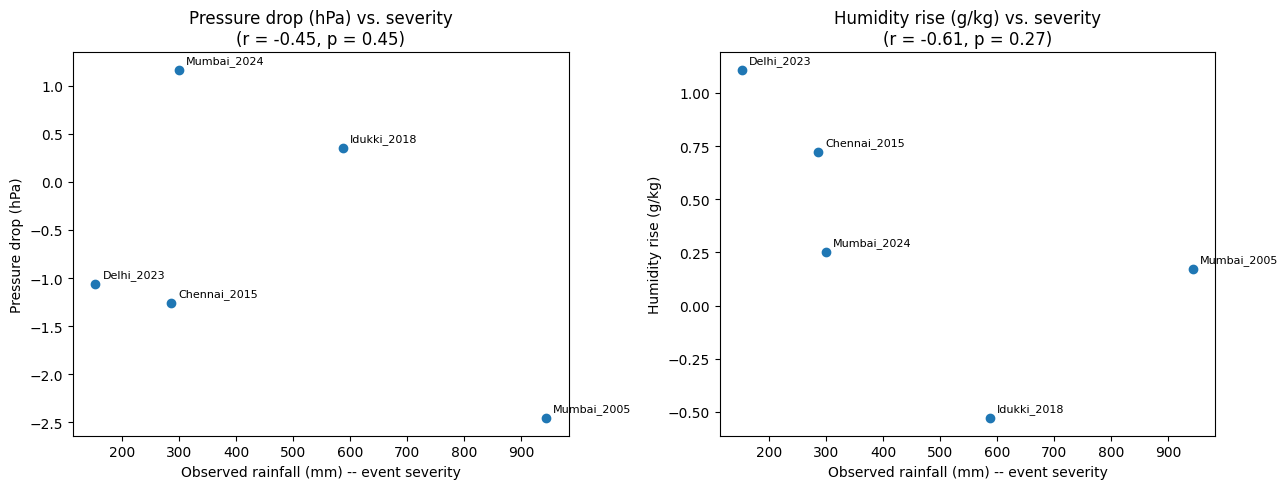

In [ ]:
import matplotlib.pyplot as plt
from scipy import stats

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col, label in zip(
    axes,
    ["Pressure change, last 24h vs first 24h (hPa)", "Humidity change, last 24h vs first 24h (g/kg)"],
    ["Pressure drop (hPa)", "Humidity rise (g/kg)"],
):
    corr, p_value = stats.pearsonr(signal_df["Observed rainfall (mm)"], signal_df[col])
    ax.scatter(signal_df["Observed rainfall (mm)"], signal_df[col])
    for _, row in signal_df.iterrows():
        ax.annotate(row["Case"], (row["Observed rainfall (mm)"], row[col]), fontsize=8, xytext=(5, 5), textcoords="offset points")
    ax.set_xlabel("Observed rainfall (mm) -- event severity")
    ax.set_ylabel(label)
    ax.set_title(f"{label} vs. severity\n(r = {corr:.2f}, p = {p_value:.2f})")
    print(f"{col}: r = {corr:.3f}, p = {p_value:.3f}")

plt.tight_layout()
plt.savefig("pangu_signal_vs_severity.png", dpi=150)
plt.show()


With only 5 events, these correlations are only an indication and not statistically strong.

## 10. Time series plot

Pressure and humidity over the whole forecast for all five cases.

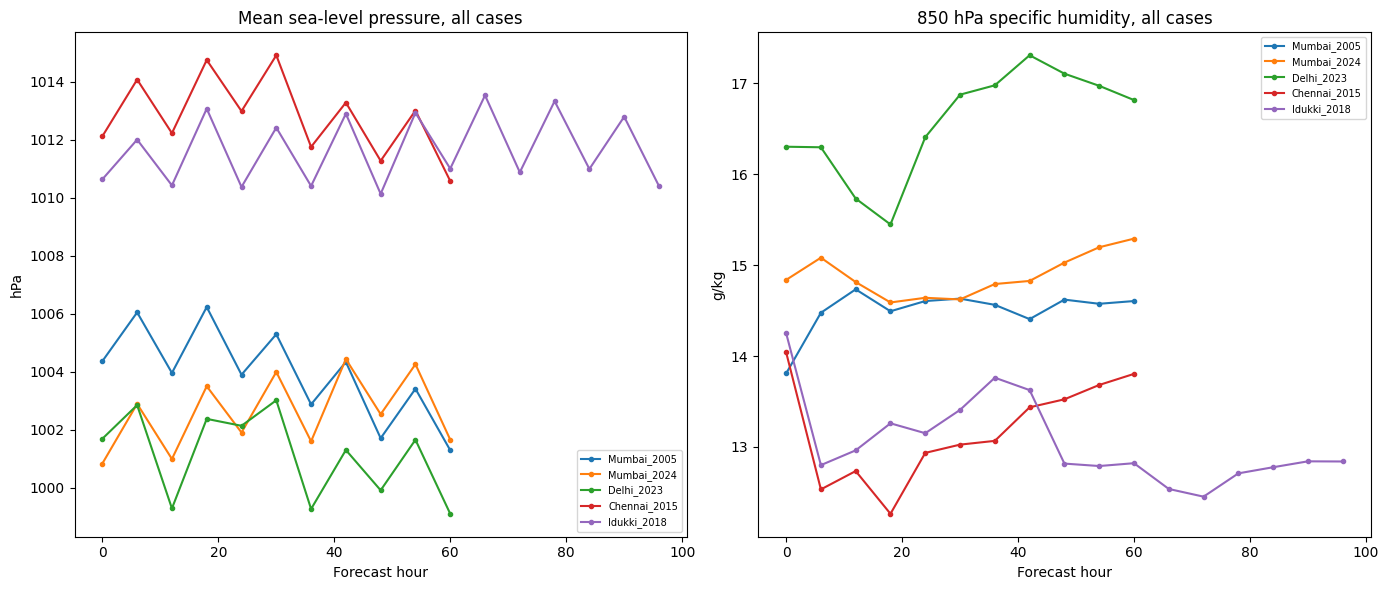

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for cid, df in synoptic_series.items():
    axes[0].plot(df["step_hour"], df["msl_hpa"], marker="o", markersize=3, label=cid)
    axes[1].plot(df["step_hour"], df["q850_gkg"], marker="o", markersize=3, label=cid)

axes[0].set_title("Mean sea-level pressure, all cases")
axes[0].set_xlabel("Forecast hour"); axes[0].set_ylabel("hPa"); axes[0].legend(fontsize=7)

axes[1].set_title("850 hPa specific humidity, all cases")
axes[1].set_xlabel("Forecast hour"); axes[1].set_ylabel("g/kg"); axes[1].legend(fontsize=7)

plt.tight_layout()
plt.savefig("pangu_all_cities_timeseries.png", dpi=150)
plt.show()


## Summary

- Pangu-Weather is tested on warning signs (pressure and humidity), not on rainfall, because it does not forecast rain.
- Section 8 gives the change in each signal for every case, and Section 9 checks whether these changes match flood size.
- Section 10 shows the full pressure and humidity forecasts, including the twice-daily pressure cycle.
- Limitations: only two variables at a single grid cell, and only five events.